# Mini-Project 1: Weather Forecast

This notebook geocodes a configured place, requests a daily forecast, and displays a table and chart. Reusable HTTP and parsing code lives in `src/weather_api.py`; offline response samples live in `tests/fixtures/`.

Run the notebook top to bottom. Before sharing or submitting, replace the email placeholder in the configuration cell with your own university email, or set `UNIVERSITY_EMAIL` in the environment. No contact details are invented here.

In [15]:
from pathlib import Path
import json
import os
import sys

import matplotlib.pyplot as plt
import pandas as pd

sys.path.insert(0, str(Path.cwd()))
from src.weather_api import (
    FORECAST_URL, GEOCODING_URL, WeatherAPIError, fetch_metno, geocode,
    get_forecast, parse_forecast, parse_geocoding, parse_metno,
    request_json, urllib_request_json,
)

# User-editable configuration: set your real university email before the MET Norway request.
LOCATION = "Dresden"
DAYS = 7
CANDIDATE_INDEX = 0
UNIVERSITY_EMAIL = os.getenv("UNIVERSITY_EMAIL", "YOUR_UNIVERSITY_EMAIL")
USER_AGENT = f"UCU-OOP-WeatherAssignment/1.0 ({UNIVERSITY_EMAIL})"
REQUEST_HEADERS = {"User-Agent": USER_AGENT}

FIXTURE_DIR = Path("tests") / "fixtures"

def read_fixture(filename):
    """Load a saved JSON response from the offline fixture directory."""
    with (FIXTURE_DIR / filename).open(encoding="utf-8") as fixture_file:
        return json.load(fixture_file)

## Part A: HTTP fundamentals

The first request uses only `urllib.request`, `urllib.parse`, and `json` inside the reusable wrapper. The following `geocode()` call makes the same search with `requests.get(..., params=..., timeout=...)`; it is also the geocoding step used below, avoiding an extra duplicate call. The request helper returns diagnostics so status, content type, and elapsed time can be inspected.

In [16]:
search_params = {"name": LOCATION, "count": 10, "language": "en", "format": "json"}
try:
    urllib_result = urllib_request_json(
        GEOCODING_URL, search_params, headers=REQUEST_HEADERS, timeout=10
    )
    print(f"urllib status: {urllib_result.status_code}")
    print(f"Content-Type: {urllib_result.content_type}")
    print(f"Response time: {urllib_result.elapsed_seconds:.3f} seconds")
except WeatherAPIError as error:
    urllib_result = None
    print(f"urllib request unavailable: {error}")

urllib status: 200
Content-Type: application/json; charset=utf-8
Response time: 0.973 seconds


### `urllib` and `requests`

`urllib` is in the standard library, so it adds no package dependency, but URL encoding, response parsing, status handling, and exception conversion take more explicit code. `urllib.parse.urlencode` makes encoding control visible, and `urllib.request.Request` lets us set headers. `requests` shortens the common path: pass a mapping through `params`, set `timeout`, inspect response metadata, and call `raise_for_status()`. It has a clearer exception hierarchy, but must be installed. Both permit explicit headers and timeouts; neither automatically makes retry policy correct. `src/weather_api.py` puts the shared retry cap, exponential delay, and custom final exception around both approaches.

## Part B: Geocode, forecast, and display

All geocoder candidates are printed with their country and region. Change `CANDIDATE_INDEX` in the configuration cell to select one. If live services are unavailable, malformed, or return no candidates, the notebook reports that fact and uses the saved Dresden sample forecast so the remaining cells still run. That fixture is clearly marked and must not be mistaken for a current forecast.

In [17]:
forecast_is_live = False
try:
    candidates = geocode(LOCATION, headers=REQUEST_HEADERS, timeout=10)
    if not candidates:
        raise WeatherAPIError(f"No location candidates found for {LOCATION!r}")
    for index, candidate in enumerate(candidates):
        region = candidate.get("admin1", "")
        country = candidate.get("country", candidate.get("country_code", ""))
        print(f"{index}: {candidate['name']}, {region}, {country} ({candidate['latitude']:.4f}, {candidate['longitude']:.4f})")
    if not 0 <= CANDIDATE_INDEX < len(candidates):
        raise ValueError("CANDIDATE_INDEX is outside the candidate list")
    location = candidates[CANDIDATE_INDEX]
    forecast_payload = get_forecast(
        location["latitude"], location["longitude"], DAYS,
        headers=REQUEST_HEADERS, timeout=10,
    )
    weather_frame = parse_forecast(forecast_payload)
    forecast_is_live = True
    place_label = f"{location['name']}, {location.get('country', '')}"
except (WeatherAPIError, ValueError) as error:
    print(f"Live forecast unavailable: {error}")
    print("Using the saved fixture below; these values are examples, not live weather.")
    location = read_fixture("geocoding.json")["results"][0]
    weather_frame = parse_forecast(read_fixture("forecast.json"))
    place_label = "Dresden (saved sample fixture)"

print(f"\nSource mode: {'live Open-Meteo' if forecast_is_live else 'offline sample'}")
print(f"Place: {place_label}")
if not weather_frame.empty:
    warmest = weather_frame.loc[weather_frame["Max temp (°C)"].idxmax()]
    wettest = weather_frame.loc[weather_frame["Precipitation (mm)"].idxmax()]
    print(
        f"Summary: high temperature peaks at {warmest['Max temp (°C)']:.1f} °C on "
        f"{warmest['Date'].date()}; greatest daily precipitation is "
        f"{wettest['Precipitation (mm)']:.1f} mm on {wettest['Date'].date()}."
    )

0: Dresden, Saxony, Germany (51.0509, 13.7383)
1: Dresden, Tennessee, United States (36.2914, -88.7081)
2: Dresden, Ohio, United States (40.1215, -82.0107)
3: Dresden, New York, United States (42.6840, -76.9558)
4: Dresden, Kansas, United States (39.6242, -100.4224)
5: Dresden, Georgia, United States (33.3515, -84.9185)
6: Dresden, Missouri, United States (38.7511, -93.3349)
7: Dresden, North Carolina, United States (36.4582, -81.5457)
8: Dresden, Texas, United States (32.0307, -96.6805)
9: Dresden, Iowa, United States (42.9791, -92.3185)

Source mode: live Open-Meteo
Place: Dresden, Germany
Summary: high temperature peaks at 19.1 °C on 2026-10-16; greatest daily precipitation is 1.9 mm on 2026-10-17.


In [18]:
weather_frame

,Date,Min temp (°C),Max temp (°C),Precipitation (mm),Max wind (km/h),Conditions
0,2026-10-14,10.0,16.0,0.1,12.0,Slight rain showers
1,2026-10-15,7.0,16.4,0.0,4.6,Overcast
2,2026-10-16,4.2,19.1,0.0,8.3,Overcast
3,2026-10-17,8.0,13.1,1.9,13.4,Slight rain
4,2026-10-18,5.9,11.9,0.0,10.8,Overcast
5,2026-10-19,5.5,12.5,0.0,8.5,Overcast
6,2026-10-20,6.5,13.0,0.0,12.3,Overcast


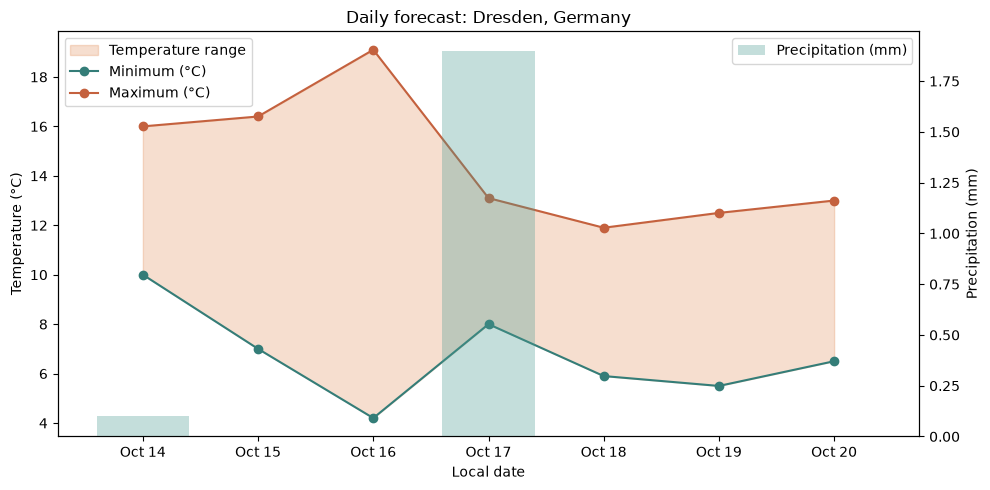

In [19]:
fig, temperature_axis = plt.subplots(figsize=(10, 5))
precipitation_axis = temperature_axis.twinx()
dates = weather_frame["Date"].dt.strftime("%b %d")
precipitation_axis.bar(dates, weather_frame["Precipitation (mm)"], color="#4a9b91", alpha=0.32, label="Precipitation (mm)")
temperature_axis.fill_between(
    range(len(weather_frame)), weather_frame["Min temp (°C)"],
    weather_frame["Max temp (°C)"], color="#e28a54", alpha=0.28, label="Temperature range"
)
temperature_axis.plot(dates, weather_frame["Min temp (°C)"], color="#347d78", marker="o", label="Minimum (°C)")
temperature_axis.plot(dates, weather_frame["Max temp (°C)"], color="#c4613e", marker="o", label="Maximum (°C)")
temperature_axis.set_ylabel("Temperature (°C)")
precipitation_axis.set_ylabel("Precipitation (mm)")
temperature_axis.set_title(f"Daily forecast: {place_label}")
temperature_axis.set_xlabel("Local date")
temperature_axis.legend(loc="upper left")
precipitation_axis.legend(loc="upper right")
fig.tight_layout()
plt.show()

**Data source:** [Open-Meteo Geocoding API](https://open-meteo.com/en/docs/geocoding-api) and [Open-Meteo Forecast API](https://open-meteo.com/en/docs). Location results use GeoNames; weather codes follow the WMO interpretation mapping in the forecast documentation. Forecast and geocoding API data: [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Open-Meteo attribution is required.

## Part C: Robustness and second source

Requests have finite timeouts, HTTP status checks, retry limits, and exponential backoff. Connection/timeouts and server errors are retried; client errors are not. Invalid coordinates are rejected before a request. Each deliberately broken case below is caught and reported so it does not stop the notebook.

In [20]:
print("Invalid city demonstration:")
try:
    invalid_candidates = geocode("zzzxq-no-such-place-74291", headers=REQUEST_HEADERS, timeout=5)
    print("No geocoder matches." if not invalid_candidates else f"Unexpected candidates: {invalid_candidates}")
except WeatherAPIError as error:
    print(f"Geocoder unavailable; empty-result handling is covered by fixtures: {error}")

print("Invalid latitude demonstration:")
try:
    get_forecast(95.0, 13.7, DAYS, headers=REQUEST_HEADERS)
except ValueError as error:
    print(f"Rejected before network access: {error}")

Invalid city demonstration:
No geocoder matches.
Invalid latitude demonstration:
Rejected before network access: latitude must be between -90 and 90 degrees


In [21]:
import requests

class OfflineSession:
    """A tiny fake session that simulates a disconnected network."""
    def get(self, *args, **kwargs):
        raise requests.ConnectionError("simulated network is offline")

try:
    request_json(
        GEOCODING_URL, search_params, session=OfflineSession(),
        max_retries=1, sleep_fn=lambda delay: None,
    )
except WeatherAPIError as error:
    print(f"Offline simulation produced the expected custom error: {error}")

Offline simulation produced the expected custom error: Request to https://geocoding-api.open-meteo.com/v1/search failed after 2 attempts: simulated network is offline


In [22]:
try:
    tiny_result = request_json(
        GEOCODING_URL, search_params, headers=REQUEST_HEADERS,
        timeout=1e-6, max_retries=0,
    )
    print(f"The tiny-timeout request happened to finish: HTTP {tiny_result.status_code}")
except (WeatherAPIError, ValueError) as error:
    print(f"Tiny timeout handled without stopping the notebook: {error}")

Tiny timeout handled without stopping the notebook: Request to https://geocoding-api.open-meteo.com/v1/search failed after 1 attempts: HTTPSConnectionPool(host='geocoding-api.open-meteo.com', port=443): Max retries exceeded with url: /v1/search?name=Dresden&count=10&language=en&format=json (Caused by ConnectTimeoutError(<HTTPSConnection(host='geocoding-api.open-meteo.com', port=443) at 0x2933fb3b110>, 'Connection to geocoding-api.open-meteo.com timed out. (connect timeout=1e-06)'))


### MET Norway Locationforecast 2.0

MET Norway's compact response is an independent forecast format with time-series values rather than Open-Meteo's daily aggregates. Its policy requires a descriptive User-Agent that includes contact information; the notebook skips the live call until the real university email has been entered. Coordinates are rounded to four decimal places and only one request is made.

In [23]:
if UNIVERSITY_EMAIL == "YOUR_UNIVERSITY_EMAIL":
    print("MET Norway request skipped: replace the email placeholder in the configuration cell first.")
else:
    try:
        metno_payload = fetch_metno(
            location["latitude"], location["longitude"],
            user_agent=USER_AGENT, timeout=10,
        )
        metno_frame = pd.DataFrame(parse_metno(metno_payload))
        print("Source: MET Norway Locationforecast 2.0; attribution: MET Norway, CC BY 4.0.")
        print(metno_frame.head().to_string(index=False))
    except (WeatherAPIError, ValueError, NameError) as error:
        print(f"MET Norway forecast unavailable: {error}")

MET Norway request skipped: replace the email placeholder in the configuration cell first.


### Offline parser checks

These assertion-based checks use only saved JSON fixtures, so their results do not depend on either weather provider being reachable. The same behaviors also have eight `unittest` checks in `tests/`.

In [24]:
geo_sample = read_fixture("geocoding.json")
empty_geo_sample = read_fixture("geocoding_empty.json")
forecast_sample = read_fixture("forecast.json")
metno_sample = read_fixture("metno.json")
sample_frame = parse_forecast(forecast_sample)
sample_metno = parse_metno(metno_sample)
assert parse_geocoding(geo_sample)[0]["name"] == "Dresden"
assert parse_geocoding(empty_geo_sample) == []
assert len(sample_frame) == 3
assert sample_frame.loc[0, "Conditions"] == "Mainly clear"
assert sample_frame.loc[1, "Conditions"] == "Slight rain"
assert sample_frame.loc[2, "Max wind (km/h)"] == 22.1
assert sample_metno[0]["Temperature (°C)"] == 11.3
assert sample_metno[0]["Symbol"] == "partlycloudy_day"
print("8 offline parsing assertions passed.")

8 offline parsing assertions passed.


## Purpose and data flow

This notebook implements a weather workflow that turns a place name into a forecast. It searches for matching locations, presents the candidate results, and requests a daily forecast for the selected location. The response is validated before conversion into a pandas DataFrame, after which a summary, table, and temperature-precipitation chart are displayed.

```mermaid
flowchart LR
    A[User configuration: place, days, email] --> B[Geocoding API]
    B --> C[Candidate list and chosen location]
    C --> D[Latitude, longitude, local timezone]
    D --> E[Open-Meteo forecast JSON]
    E --> F[Validate and parse into pandas]
    F --> G[Summary, table, temperature and rain chart]
    H[Saved JSON fixtures] --> F
```

The saved fixture files provide a fallback when the live API is unavailable. They are clearly marked as sample data and are used to validate parsing and error-handling behavior without a live network dependency.


## HTTP choices and reliability

Both urllib and requests are used to compare the same geocoding task. urllib is part of the standard library, while requests is more concise for params, timeouts, and status handling. In both cases, requests use short timeouts, retry transient failures a limited number of times, and raise a custom error when the request fails or the JSON is invalid.

The response data is validated before use. Coordinates outside the valid range are rejected, forecast arrays must all match in length, and bad responses are handled without stopping the notebook.


## Licensing, attribution, and product implications

The data used here comes from Open-Meteo and MET Norway, and both providers require attribution under the CC BY 4.0 license. The source and license are included where relevant, and the weather labels remain clear and traceable. Open-Meteo also imposes free-use limits, so a commercial or high-volume product would require a different plan.

The MET Norway request is only sent when a valid university email is provided in the configuration cell. This complies with the service requirement for a descriptive User-Agent with contact information and avoids submitting fabricated or incomplete details.


## Privacy, limitations, and conclusion

This notebook sends the chosen place name and coordinates to external weather services, so the location is kept to a city-level query and unnecessary details are not stored. A key limitation is that the candidate index is selected manually, and different providers do not always aggregate data in exactly the same way.

Overall, the project demonstrates the full workflow: geocoding, fetching data, validating the response, parsing it into a table, plotting the forecast, and handling offline test data when live access is not available.


## References

- Open-Meteo. Geocoding API documentation. https://open-meteo.com/en/docs/geocoding-api
- Open-Meteo. Forecast API documentation and WMO weather-code mapping. https://open-meteo.com/en/docs
- Open-Meteo. License and terms. https://open-meteo.com/en/licence and https://open-meteo.com/en/terms
- MET Norway. Locationforecast 2.0 documentation. https://api.met.no/weatherapi/locationforecast/2.0/documentation
- MET Norway. Terms of Service and FAQ. https://api.met.no/doc/TermsOfService and https://api.met.no/doc/FAQ
- Creative Commons. Attribution 4.0 International (CC BY 4.0). https://creativecommons.org/licenses/by/4.0/

Documentation reviewed on 10 October 2026. Terms and policies should be checked again before any public deployment or commercial reuse.
